# Phân loại rác bằng CNN tự xây
CNN thuần: 4 khối Conv-BN-ReLU-MaxPool + Global Average Pooling + Dropout, huấn luyện từ đầu (không pretrained).

Dữ liệu: **Garbage Classification** (12 loại rác, ~15.5k ảnh) trong `data/garbage/`.

In [1]:
import torch, torch.nn as nn
from torchvision import models
import common as C
print(C.DEVICE)

cuda


## 1. Dữ liệu

12 lớp: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
{'train': 10864, 'val': 2328, 'test': 2328}


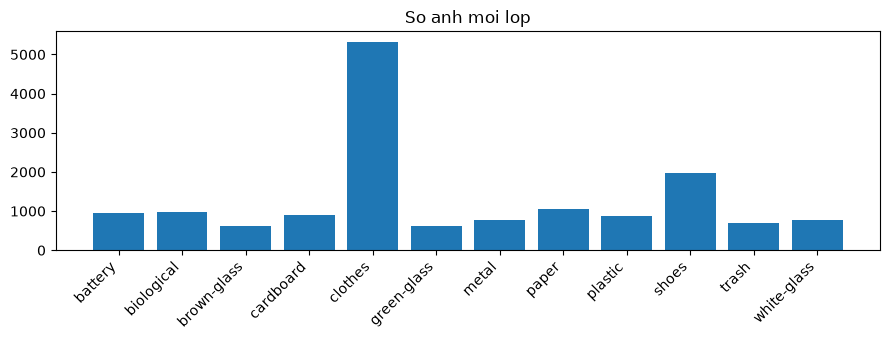

{'battery': 945,
 'biological': 985,
 'brown-glass': 607,
 'cardboard': 891,
 'clothes': 5325,
 'green-glass': 629,
 'metal': 769,
 'paper': 1050,
 'plastic': 865,
 'shoes': 1977,
 'trash': 697,
 'white-glass': 780}

In [2]:
IMG_SIZE, BATCH_SIZE = 128, 64
classes, loaders, y_train = C.get_loaders(IMG_SIZE, BATCH_SIZE)
print(len(classes), 'lớp:', classes)
print({k: len(v.dataset) for k, v in loaders.items()})
C.plot_class_distribution(classes)

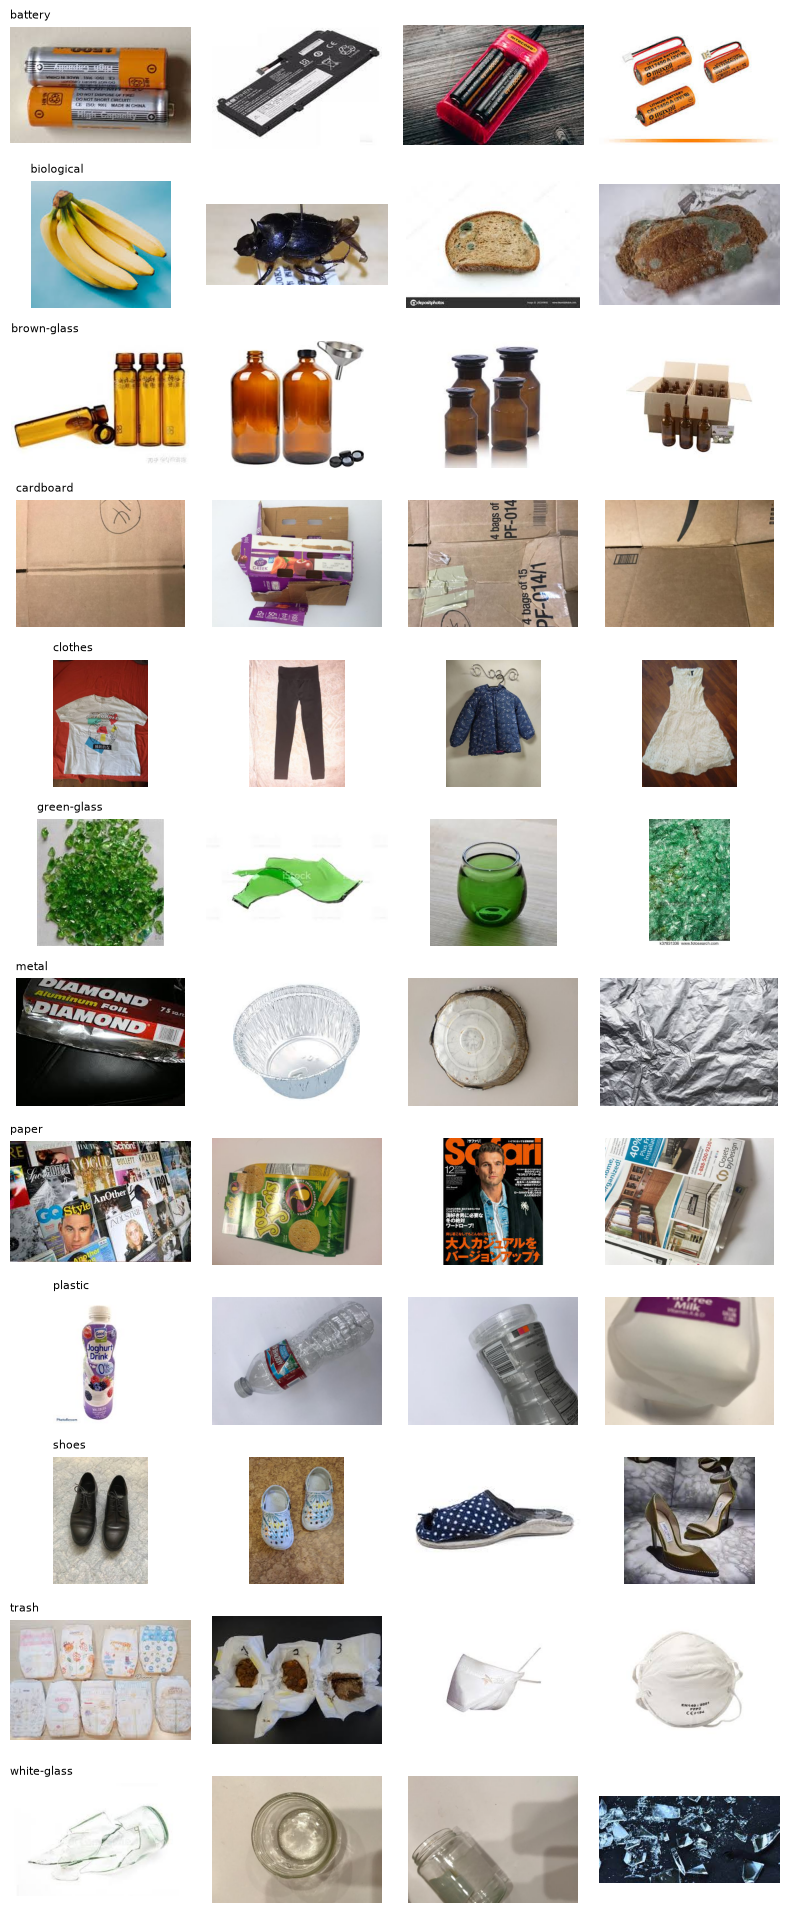

In [3]:
C.show_samples(classes)

## 2. Mô hình

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, n):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, n))
    def forward(self, x):
        return self.head(self.features(x))

model = SimpleCNN(len(classes))

In [5]:
print(f'{sum(p.numel() for p in model.parameters())/1e6:.2f}M tham số')

1.18M tham số


### Giải thích kiến trúc CNN

**Mỗi khối** có cùng cấu trúc:

`Conv 3×3 → BatchNorm → ReLU → Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2`

- **Conv 3×3 (padding=1)**: lọc đặc trưng, giữ nguyên kích thước ảnh. Hai conv 3×3 liên tiếp có vùng nhìn tương đương conv 5×5 nhưng ít tham số hơn.
- **BatchNorm**: chuẩn hóa đầu ra conv, giúp train ổn định và hội tụ nhanh.
- **ReLU**: hàm kích hoạt phi tuyến `max(0, x)`.
- **MaxPool 2×2**: lấy giá trị lớn nhất mỗi ô 2×2, giảm một nửa chiều dài và rộng.

**Dòng chảy dữ liệu qua 4 khối** (ảnh vào 128×128):

| Khối | Kênh vào → ra | Kích thước đầu ra | Học được gì |
|---|---|---|---|
| 1 | 3 → 32 | 64×64×32 | Đặc trưng mức thấp: cạnh, góc, màu |
| 2 | 32 → 64 | 32×32×64 | Kết cấu, hoa văn đơn giản |
| 3 | 64 → 128 | 16×16×128 | Bộ phận, hình dạng (nắp chai, nếp vải) |
| 4 | 128 → 256 | 8×8×256 | Đặc trưng mức cao, đặc trưng cho từng loại rác |

Sau mỗi khối, kích thước không gian giảm một nửa và số kênh tăng gấp đôi.

**Phần đầu ra (head):** `AdaptiveAvgPool2d(1) → Flatten → Dropout(0.4) → Linear(256 → 12)`

- **Global Average Pooling**: lấy trung bình mỗi bản đồ 8×8 thành 1 số, tạo vector 256 chiều. Ít tham số hơn flatten + Linear lớn, giảm overfit.
- **Dropout 0.4**: tắt ngẫu nhiên 40% nơ-ron khi train để chống học vẹt.
- **Linear 256 → 12**: 12 điểm số, mỗi điểm ứng với một loại rác.

**Vì sao 4 khối?** Ảnh 128 chia đôi 4 lần còn 8×8, đủ nhỏ để gộp thông tin mà chưa mất hết chi tiết. Mô hình khoảng 1,2 triệu tham số, nhỏ hơn ResNet18 (~11M) và EfficientNet-B0 (~4M), đóng vai trò baseline. Không có skip connection như ResNet, không có khối MBConv như EfficientNet, nên đây là CNN thuần.

In [6]:
x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
print('input', tuple(x.shape))
for i, blk in enumerate(model.features, 1):
    x = blk(x)
    print(f'khối {i}', tuple(x.shape))
print('head  ', tuple(model.head(x).shape))

input (1, 3, 128, 128)
khối 1 (1, 32, 64, 64)
khối 2 (1, 64, 32, 32)
khối 3 (1, 128, 16, 16)
khối 4 (1, 256, 8, 8)
head   (1, 12)


## 3. Huấn luyện
Dùng AdamW + OneCycleLR, mixed precision, loss có trọng số lớp (dữ liệu mất cân bằng: `clothes` nhiều hơn hẳn các lớp khác). Chọn checkpoint theo val accuracy.

In [7]:
EPOCHS, LR = 20, 0.002
model, hist, t = C.train_model('cnn', model, loaders, y_train, len(classes), EPOCHS, LR)
print(f'Thời gian train: {t/60:.1f} phút')

ep 01/20 | train loss 1.710 acc 0.409 | val loss 1.423 acc 0.498
ep 02/20 | train loss 1.479 acc 0.498 | val loss 1.446 acc 0.527
ep 03/20 | train loss 1.408 acc 0.529 | val loss 1.342 acc 0.574
ep 04/20 | train loss 1.348 acc 0.546 | val loss 1.555 acc 0.494
ep 05/20 | train loss 1.313 acc 0.554 | val loss 1.392 acc 0.516
ep 06/20 | train loss 1.245 acc 0.583 | val loss 1.083 acc 0.665
ep 07/20 | train loss 1.164 acc 0.617 | val loss 1.443 acc 0.578
ep 08/20 | train loss 1.101 acc 0.637 | val loss 1.475 acc 0.524
ep 09/20 | train loss 1.026 acc 0.664 | val loss 1.048 acc 0.605
ep 10/20 | train loss 0.982 acc 0.678 | val loss 1.424 acc 0.554
ep 11/20 | train loss 0.905 acc 0.707 | val loss 1.386 acc 0.618
ep 12/20 | train loss 0.866 acc 0.721 | val loss 0.889 acc 0.735
ep 13/20 | train loss 0.814 acc 0.742 | val loss 0.777 acc 0.755
ep 14/20 | train loss 0.737 acc 0.768 | val loss 0.803 acc 0.729
ep 15/20 | train loss 0.696 acc 0.781 | val loss 0.895 acc 0.732
ep 16/20 | train loss 0.6

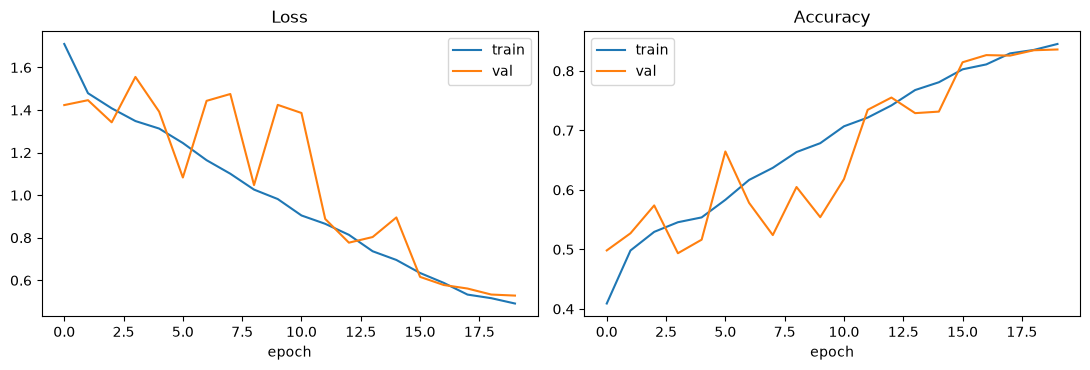

In [8]:
C.plot_history(hist)

## 4. Đánh giá trên tập test

              precision    recall  f1-score   support

     battery     0.8710    0.7606    0.8120       142
  biological     0.7875    0.8571    0.8208       147
 brown-glass     0.8421    0.8791    0.8602        91
   cardboard     0.7826    0.8120    0.7970       133
     clothes     0.9508    0.8698    0.9085       799
 green-glass     0.9020    0.9684    0.9340        95
       metal     0.6797    0.7500    0.7131       116
       paper     0.7278    0.8344    0.7774       157
     plastic     0.7481    0.7538    0.7510       130
       shoes     0.7566    0.7744    0.7654       297
       trash     0.7946    0.8558    0.8241       104
 white-glass     0.7317    0.7692    0.7500       117

    accuracy                         0.8308      2328
   macro avg     0.7979    0.8237    0.8095      2328
weighted avg     0.8371    0.8308    0.8325      2328



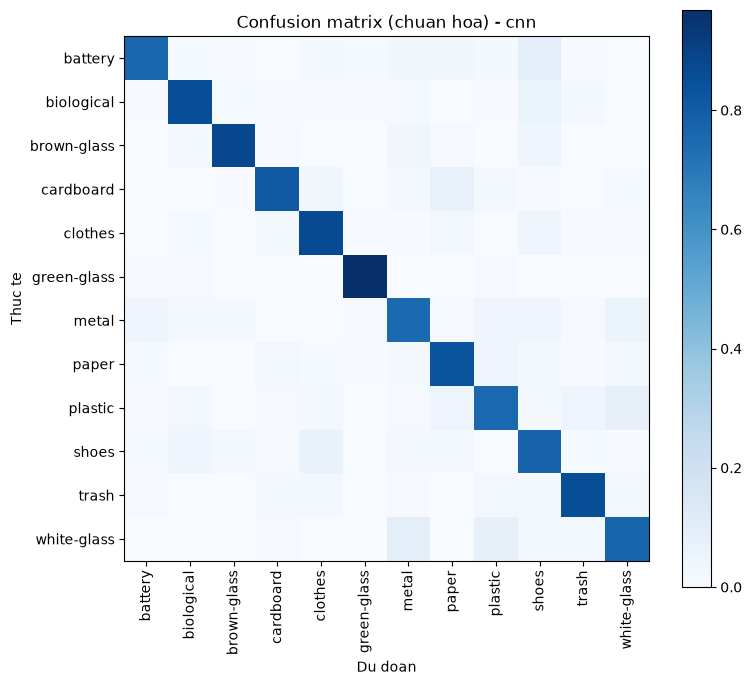

Test accuracy: 0.8308 | macro F1: 0.8095


In [9]:
res = C.evaluate('cnn', model, loaders['test'], classes, hist, t)

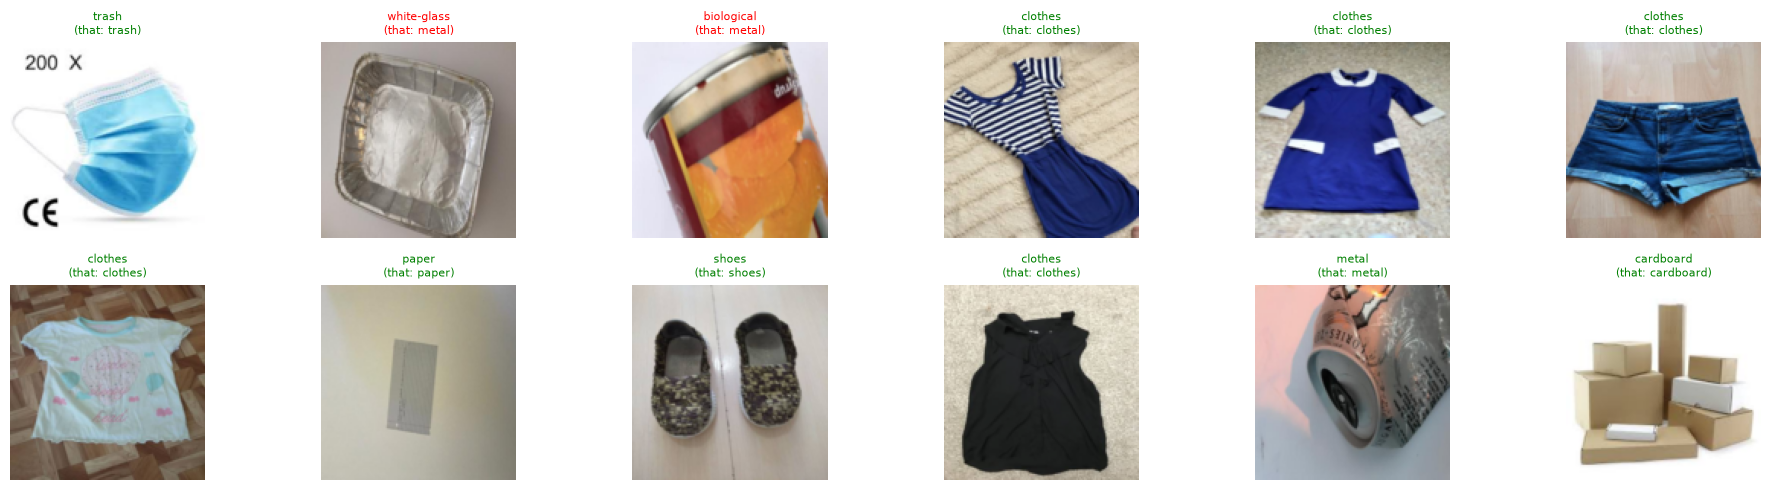

In [10]:
C.show_predictions(model, loaders['test'], classes)

## 5. Nhận xét

**Kết quả:** CNN tự xây đạt **83,1% accuracy** và **macro F1 = 0,809** trên tập test (1,18 triệu tham số, train 20 epoch, khoảng 16,7 phút). Đây là mô hình có kết quả thấp nhất trong 3 mô hình.

**Quá trình huấn luyện:** accuracy train cuối là 84,5%, val là 83,6%, hai số sát nhau nên mô hình **không bị overfit**. Ngược lại, mô hình hơi **underfit**: loss vẫn đang giảm ở epoch 20, nghĩa là mạng nhỏ và train từ đầu chưa học hết đặc trưng. Val loss dao động mạnh ở nửa đầu do learning rate cao (OneCycleLR) và ổn định lại khi learning rate giảm.

**Theo từng lớp (F1):** tốt nhất là `green-glass` (0,934) và `clothes` (0,908); yếu nhất là `metal` (0,713), `white-glass` (0,750), `plastic` (0,751) và `shoes` (0,765). Các lớp yếu đều là vật liệu trong suốt hoặc phản chiếu, hình dạng đa dạng, khó phân biệt chỉ bằng đặc trưng học từ đầu.

**Lỗi hay gặp:** nhầm nhiều nhất là `clothes` bị đoán thành `shoes` (33 ảnh), `paper` (20) và `cardboard` (18); `shoes` bị đoán thành `clothes` (20). Một phần vì `clothes` có nhiều ảnh nhất (khoảng 5.300) nên mô hình hay "đoán đại" vào lớp này dù đã dùng loss có trọng số.

**Kết luận:** CNN thuần đủ làm mốc so sánh nhưng chưa đủ tốt khi dữ liệu có nhiều lớp giống nhau về hình thức. Việc train từ đầu cần nhiều epoch và nhiều dữ liệu hơn.